# Exercise 1 (10 points)

In this exercise, we will practice refactoring concepts in analytics/data science tasks. Consider the following scenario. You're given a dataset of employee information, and you need to transform it to prepare for analysis. The initial function, `transform_employee_data`, does this by:

- Converting salary values to floats.
- Standardizing department names to lowercase.
- Adding a new column called `salary_level` based on salary thresholds.

However, the function is not well-structured or efficient. Your task is to refactor it to improve its design. Here’s the initial, unrefactored code:

```
import pandas as pd

def transform_employee_data(df):
    # Convert salary to float
    for i in range(len(df)):
        df.loc[i, 'salary'] = float(df.loc[i, 'salary'])

    # Standardize department names
    for i in range(len(df)):
        df.loc[i, 'department'] = df.loc[i, 'department'].lower()

    # Add salary level column
    for i in range(len(df)):
        salary = df.loc[i, 'salary']
        if salary < 50000:
            df.loc[i, 'salary_level'] = 'low'
        elif 50000 <= salary < 100000:
            df.loc[i, 'salary_level'] = 'medium'
        else:
            df.loc[i, 'salary_level'] = 'high'

    return df

```

Refactoring instructions:

- **Remove loops**: The function uses loops which can be slow with large datasets. Use `pandas` vectorized operations to improve performance.
- **Simplify conditional**: Replace conditional logic with `pd.cut` for better readability.
- **Rename the function**: Use a more descriptive name.

Then, apply the refactored function to following data:

```
data = {'employee_id': [1, 2, 3],
        'salary': ['48000', '75000', '120000'],
        'department': ['Sales', 'Engineering', 'Marketing']
}
```

The expected outcome is shown below.

| employee_id | salary | department | salary_level |
| --- | --- | --- | --- |
| 1 | 48000.0 | sales | low |
| 2 | 75000.0 | engineering | medium |
| 3 | 120000.0 | marketing | high |



In [2]:

import pandas as pd


data = {
    'employee_id': [1, 2, 3],
    'salary': ['48000', '75000', '120000'],
    'department': ['Sales', 'Engineering', 'Marketing']
}

df = pd.DataFrame(data)
df



,employee_id,salary,department
0,1,48000,Sales
1,2,75000,Engineering
2,3,120000,Marketing


In [3]:

def prepare_employee_data(df):
    df = df.copy()

    df['salary'] = df['salary'].astype(float)

    df['department'] = df['department'].str.lower()

    df['salary_level'] = pd.cut(
        df['salary'],
        bins=[float('-inf'), 50000, 100000, float('inf')],
        labels=['low', 'medium', 'high'],
        right=False
    )

    return df


In [4]:

cleaned_df = prepare_employee_data(df)

cleaned_df


,employee_id,salary,department,salary_level
0,1,48000.0,sales,low
1,2,75000.0,engineering,medium
2,3,120000.0,marketing,high


In [5]:

print("Original Data:")
print(df)

print("\nRefactored Data:")
print(cleaned_df)


Original Data:
   employee_id  salary   department
0            1   48000        Sales
1            2   75000  Engineering
2            3  120000    Marketing

Refactored Data:
   employee_id    salary   department salary_level
0            1   48000.0        sales          low
1            2   75000.0  engineering       medium
2            3  120000.0    marketing         high


# Exercise 2

In this exercise, we will practice `polars` operations.

### Exercise 2(a) (2 points)

Load `polars`, `matplotlib.pyplot` and `seaborn`.

In [7]:


%pip install seaborn

import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns


### Exercise 2(b) (2 points)

Read the `diamond.csv` data file and create a data frame called `df`. Report the shape of `df`.

In [10]:

%pip install pyarrow


In [12]:

import pandas as pd
import polars as pl

diamonds_pd = pd.read_csv("diamond.csv")

df = pl.DataFrame(diamonds_pd.to_dict(orient="list"))

print("Dataset shape:", df.shape)


Dataset shape: (6000, 8)


### Exercise 2(c) (3 points)

Create the frequency table of `Cut`.

In [13]:

cut_frequency = df.group_by("Cut").len()

print(cut_frequency)


shape: (5, 2)
┌─────────────────┬──────┐
│ Cut             ┆ len  │
│ ---             ┆ ---  │
│ str             ┆ u32  │
╞═════════════════╪══════╡
│ Good            ┆ 708  │
│ Signature-Ideal ┆ 253  │
│ Very Good       ┆ 2428 │
│ Ideal           ┆ 2482 │
│ Fair            ┆ 129  │
└─────────────────┴──────┘


### Exercise 2(d) (3 points)

Report the average `Price` based on `Color`.

In [14]:

average_price_color = df.group_by("Color").agg(
    pl.col("Price").mean().alias("Average Price")
)

print(average_price_color)


shape: (6, 2)
┌───────┬───────────────┐
│ Color ┆ Average Price │
│ ---   ┆ ---           │
│ str   ┆ f64           │
╞═══════╪═══════════════╡
│ G     ┆ 12520.050633  │
│ D     ┆ 15255.783661  │
│ E     ┆ 11539.190231  │
│ F     ┆ 12712.241856  │
│ H     ┆ 10487.347544  │
│ I     ┆ 8989.636364   │
└───────┴───────────────┘


### Exercise 2(e) (3 points)

Report the average `Price` based on `Cut` and `Color`.

In [15]:

average_price_cut_color = df.group_by(
    ["Cut", "Color"]
).agg(
    pl.col("Price").mean().alias("Average Price")
)

print(average_price_cut_color)


shape: (30, 3)
┌─────────────────┬───────┬───────────────┐
│ Cut             ┆ Color ┆ Average Price │
│ ---             ┆ ---   ┆ ---           │
│ str             ┆ str   ┆ f64           │
╞═════════════════╪═══════╪═══════════════╡
│ Fair            ┆ E     ┆ 5370.625      │
│ Ideal           ┆ G     ┆ 13570.310145  │
│ Very Good       ┆ G     ┆ 12354.013841  │
│ Very Good       ┆ F     ┆ 12413.905495  │
│ Good            ┆ I     ┆ 8174.113043   │
│ …               ┆ …     ┆ …             │
│ Signature-Ideal ┆ E     ┆ 11261.914286  │
│ Fair            ┆ H     ┆ 5908.5        │
│ Ideal           ┆ I     ┆ 9459.588378   │
│ Signature-Ideal ┆ H     ┆ 9112.688889   │
│ Fair            ┆ G     ┆ 7345.52381    │
└─────────────────┴───────┴───────────────┘


### Exercise 2(f) (3 points)

Compute the correlation between `Carat Weight` and `Price`. 

In [16]:

correlation = df.select(
    pl.corr("Carat Weight", "Price")
)

print(correlation)


shape: (1, 1)
┌──────────────┐
│ Carat Weight │
│ ---          │
│ f64          │
╞══════════════╡
│ 0.858562     │
└──────────────┘


### Exercise 2(g) (4 points)

Create a scatter plot between `Carat Weight` and `Price`.

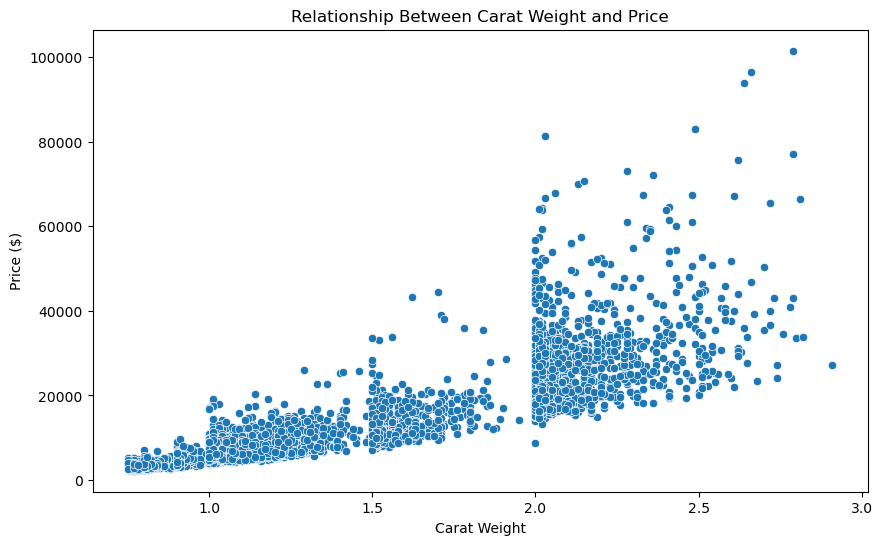

In [17]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=diamonds_pd,
    x="Carat Weight",
    y="Price"
)

plt.title("Relationship Between Carat Weight and Price")
plt.xlabel("Carat Weight")
plt.ylabel("Price ($)")

plt.show()


# Exercise 3 (5 points)

In this exercise, we will discuss design and refactoring concepts in applied data science.

Explain what the *single responsibility principle* means for a data science workflow, and why splitting a long, monolithic analysis script into small, focused functions (e.g., loading, cleaning, feature engineering, modeling) makes the code easier to test, reuse, and maintain. In your answer, also explain why refactoring should preserve the code's behavior, and how you would verify that a refactored function still produces the same results as the original.

The single responsibility principle means that each function should have one main job. This makes the code easier to read, understand, and fix when something goes wrong.

Refactoring means cleaning up code without changing its results. Breaking larger code into smaller functions makes it easier to manage and reuse.

To make sure the code still works, I would run both the original and updated versions and compare their results to see if they match.